<a href="https://colab.research.google.com/github/yasuhiroinoue/AppMathSci/blob/main/%E5%BF%9C%E7%94%A8%E6%95%B0%E7%90%86(11_08).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**応用数理科学(第6回)**##

前半の講義では、微分方程式を用いた決定論的な数理モデルを扱った。後半の講義では、「ゆらぎ」があるときの数理モデルを考えていこう。そのための準備として、モデル評価の基準を解説する。

###**モデル評価の基準**###
観測データは、様々な原因で誤差を含む。いっそのこと、観測値とは、ある確率分布に従う確率変数の実現値と考えることにしよう。この真の確率分布を近似する確率分布（モデル）を求めたとき、それがどの程度“良いのか”をどのような視点で評価すれば良いか？

##**Kullback-Leibler Divergence (カルバック・ライブラー ダイバージェンス)**##
Kullback-Leiblerダイバージェンス(以後、KLダイバージェンス)$D_{KL}(p||q)$は、一方の確率分布$q$が他方の確率分布$p$からどれほど異なるかを表す量である。
$$D_{KL}(p||q)=\sum_ip_i\log\frac{p_i}{q_i}$$
$D_{KL}(p||q)$は非負値を取ることを次のように証明できる。
$x>0$に対して、$\log x \leq x - 1$であるから
$$D_{KL}(p||q)=\sum_ip_i\log\frac{p_i}{q_i}=-\sum_ip_i\log\frac{q_i}{p_i} \geq -\sum_ip_i(\frac{q_i}{p_i}-1)=0$$
となる。等号成立は、$p_i=q_i$に限られる。このように非負値であるが、距離の公理は満たさないので、決して、カルバック・ライブラー「距離」と**呼んではいけない**。

###**対数尤度**###
いま、$p$を真の分布、$q$をモデル分布としよう。
$D_{KL}(p||q)\geq 0$より
$$\sum_i p_i\log p_i \geq \sum_i p_i \log q_i$$となる。
両辺ともに、真の分布$p$による期待値計算の形をしているので、
$$E[\log p] \geq E[\log q] \tag{1}$$
と書こう。$E[\cdot]$は真の分布$p$による期待値である。

ここで、$l(q) = \sum_i \log q_i$を対数尤度といい、$E[\log q]$を**平均対数尤度**という。

この不等式から、平均対数尤度の上限値は、$E[\log p]$である。
したがって、平均対数尤度が大きければ大きいほど、モデル分布$q$は真の分布に近いことを表す。

$n$個の観測データが得られたときの対数尤度の$1/n$倍は、$n\rightarrow \infty$で$$\frac{1}{n}\sum_{j=1}^n\log{q(x_j)}=\sum_i \frac{n_i}{n}\log{q_i}\rightarrow E[\log q]$$となる。（大数の法則）

極限を取る前の等式において、左辺から右辺に式変形するときに、事象$x_j$の和から状態$i$の和に変えているので、良く見ること。
（例：サイコロを振る実験で、データindex=1でサイコロの目=3、index=2でサイコロの目=4のように記録順で和を取るのが左辺、サイコロの目=1は$n_1$回でしたと和を取るのが右辺）

###**例題**###
A君とB君は、阪神 対 巨人における阪神の勝率を予想した。A君は、2割だという。B君は、4割だという。

阪神の勝率の真値が3割とすると、A君とB君のどちらの予想がより正しいと言えるのか？

対数尤度で考えなさい。

###**例題解答**###


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

p = 0.3
q_A = 0.2
q_B = 0.4
l_A = p*np.log(q_A)+(1-p)*np.log(1-q_A)
l_B = p*np.log(q_B)+(1-p)*np.log(1-q_B)

print("A: ", l_A)
print("B: ", l_B)

if l_A > l_B:
  print('A君')
elif l_A < l_B:
  print('B君')
else:
  print('どっちもどっち')

A:  -0.6390318596501768
B:  -0.63246515619844
B君


###**演習**###

阪神の勝率の真値は誰にも分からないので、実際のデータをもとに考えよう。2025年においては、阪神 対 巨人は阪神17勝、巨人8勝であった。A君とB君のどちらの予想のほうが正しかったと言えそうか。
（参考データ[NPB](https://npb.jp/bis/2025/stats/std_c.html)）


In [2]:
##ここに演習解答しなさい##
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

p = 17/25
q_A = 0.2
q_B = 0.4
l_A = p*np.log(q_A)+(1-p)*np.log(1-q_A)
l_B = p*np.log(q_B)+(1-p)*np.log(1-q_B)

print("A: ", l_A)
print("B: ", l_B)

if l_A > l_B:
  print('A君')
elif l_A < l_B:
  print('B君')
else:
  print('どっちもどっち')

A:  -1.1658237168757353
B:  -0.7865418972795425
B君


##***最尤法***##
式(1)は、対数尤度が大きければ大きいほど、モデル分布は真の分布に近づくことを表していた。そこで、対数尤度を最大化すると、真の分布に近似的にもっとも近い分布が得られそうだ。

いま、確率変数$(X_1, X_2, \cdots, X_n)$の同時確率密度関数が$f(x_1,\cdots,x_n|\theta)$で与えられているとする。$\theta$は同時確率密度関数のパラメータである（平均値や分散）。観測データ($x_1,\cdots,x_n$)は与えられたものとして固定し、$f$を$\theta$の関数と考えるのが尤度$L(\theta|\{x_i\})$である。
$$L(\theta|\{x_i\})=f(x_1,\cdots,x_n|\theta)$$
確率変数が独立の場合は、各密度関数の掛算となるので
$$L(\theta|\{x_i\})=\prod_i f(x_i|\theta)$$
上式の対数を取ると、すでに求めた対数尤度の式が再び得られる。
$$\log L(\theta|\{x_i\})=\sum_i\log f(x_i|\theta)\tag{2}$$

最尤法は、対数尤度を最大化するようにパラメータ$\theta$を決める手法で、以下の尤度方程式の解として、最尤推定値$\hat \theta$を決定する。
$$\frac{\partial \log L}{\partial \theta}=0$$


###**例（2項分布）**###
コインが1枚あり、10回なげたところ、(表, 表, 裏, 表, 表, 裏, 裏, 表, 表, 表）と出た。コインの表が出る確率$\theta$とする。尤度$L$は
$$L(\theta)=\theta^7(1-\theta)^3$$
であるから
$$\frac{\partial \log L}{\partial \theta}=\frac{7}{\theta}-\frac{3}{1-\theta}=0$$より、$$\hat \theta = 7/10$$ですね。

###**例（正規分布）**###
$$f(x|\mu, \sigma^2)=\frac{1}{\sqrt{2\pi \sigma^2}}\exp{(-\frac{(x-\mu)^2}{2\sigma^2})}$$
$$\log L = -\frac{n}{2}\log{2\pi\sigma^2}-\frac{1}{2\sigma^2}\sum_{i=1}^n(x_i-\mu)^2\tag{3}$$
となる。尤度方程式より
$$\frac{\partial \log L}{\partial \mu} =\frac{1}{\sigma^2}\sum_i(x_i-\mu)=0$$
$$\frac{\partial \log L}{\partial \sigma^2} =-\frac{n}{2\sigma^2}+\frac{1}{2\sigma^4}\sum_i(x_i-\mu)^2=0$$
となるので
$$\hat\mu=\frac{1}{n}\sum_{i=1}^nx_i$$
$$\hat \sigma^2 = \frac{1}{n}\sum_{i=1}^n(x_i-\mu)^2$$
が得られる。

なお、ここから最小二乗法と呼ばれる手法との関係が見えてくる。式(3)の右辺第2項目は二乗誤差となっているので、最小二乗法は、誤差分布が正規分布と仮定したときの最尤法と見なすことができる。逆に言えば、誤差分布が正規分布でないものに、最小二乗法を適用した場合には、得られたモデルの使い方には注意しよう。



###**演習**###
[NPB](https://npb.jp/bis/2020/stats/std_c.html)のデータを用いて、球団の勝利・敗北・引分の確率を最尤法で推定しなさい。




###**未知データに対するモデルの当てはまりの良さ**###
真の分布から生成される標本をある時点で得て、これに対して最尤モデルを作ったとする。この最尤モデルが、将来に得られるデータに対して、どれほど良いモデルとなっているのか？（予測・説明可能か）

その良さの評価（モデル選択の基準）として、最尤モデルの平均対数尤度を考えよう。これは、最尤モデルを作った時点よりあとに得られるだろうデータも含めて評価することに相当する。

実は、最尤モデルを作ったときに得られる最大対数尤度の期待値をとっても、平均対数尤度とは一致しない。

最大対数尤度は、得られたデータに対して、最大化しているので、まだ得られていないデータも含む平均対数尤度より、値が大きく出やすい。この傾向（偏り）の大きさは、$n$個のデータに対する対数尤度の単位で測ると、モデルの自由パラメータの数に等しい。

実際に、真の分布が正規分布だと分かっている状況で、最尤法を行い、最大対数尤度と平均対数尤度の関係を見てみよう。

###**数値実験（最大対数尤度と平均対数尤度）**###
次のコードを動かし、最大対数尤度と平均対数尤度の差(バイアス)を、モデルのパラメータの数$k$に対してプロットしてみよう。

#####**前提**#####
生成されるデータの確率密度関数は正規分布であるとすると
例（正規分布）の性質から、最小二乗法を使って、最尤推定が行える。
$n$個のデータ点$(x_i, y_i)$において、$x$は確定値のデータセットで、確率変数$Y$が値$y$を取るとしよう。このとき、$Y$の確率密度関数は、平均$\mu=\mu(x|\theta^*)$, 分散$\sigma^2$の正規分布とする。分散は既知とする。


#####**アルゴリズムの概略**#####
最初に得られたデータ$X=(y_1,\cdots,y_n)$を用いて、最小二乗法により、$m$次の多項式$y=f_m(x|\theta)$における最尤推定量$\hat \theta(X)$を求め、最大対数尤度
$$l(\hat\theta)=\sum_{i=1}^n\log f(y_i|\hat\theta)$$
の計算を行う。
次に、$Y$の真の確率分布から新たにsample個のデータセット$Z=(z_1,\cdots,z_n)$を生成して、これらを用いて、最尤モデルの平均対数尤度（$n$個のデータに対する対数尤度の、将来のデータ$Z$についての期待値）
$$l^*(\hat\theta)=E_Z\left[\sum_{i=1}^n\log f(z_i|\hat\theta)\right]=nE_Z[\log f(Z|\hat\theta)]$$
を計算する。
モデルの自由なパラメータの数は多項式の係数の個数$k=m+1$となる。

以上の操作をsys_sample人の試験者が独立に行い、
sys_sample個の最大対数尤度と平均対数尤度から、それぞれ平均を求める。
$\rightarrow$最大対数尤度の期待値$E_X[l(\hat\theta)]$、平均対数尤度の期待値$E_X[l^*(\hat\theta)]$

つまり、この数値実験には2種類の「ゆらぎ」が入っている。最尤推定量$\hat\theta(X)$は手元のデータ$X$の関数（確率変数）なので、その平均を取るのが外側の期待値$E_X$であり、将来のデータ$Z$についての平均が内側の期待値$E_Z$である。下のコードでは、`sys_sample`個のデータセット$X$をまとめて生成する部分が$E_X$、各$X$に対して`sample`個のデータセット$Z$を生成する部分が$E_Z$に対応する。

#####**実装上の注意**#####
下のコードでは、$m$次多項式の最小二乗法を、計画行列（ヴァンデルモンド行列）$V$（第$i$行が$(x_i^m,\cdots,x_i,1)$）を用いて$\|Y-V\theta\|^2$を最小化する線形最小二乗問題として解いている（`np.linalg.lstsq`）。これは`np.polyfit`が内部で行っている計算と同じであるが、`sys_sample`人分のデータを1つの行列にまとめて一度に解いているので、試行回数を増やしても実行時間は10秒程度である。`sys_sample`, `sample`, `sigma`, `m_ini`などを変えて、結果がどう変わるか確かめてみよう。

 k   bias   (standard error)
 4    3.96  (0.11)
 5    4.93  (0.09)
 6    5.91  (0.09)
 7    6.93  (0.09)
 8    7.89  (0.09)
 9    8.94  (0.09)
10   10.00  (0.09)
11   10.96  (0.09)
12   11.99  (0.09)
13   13.02  (0.09)
14   13.98  (0.09)
15   14.99  (0.09)
16   15.99  (0.09)
17   16.95  (0.09)
18   17.92  (0.09)
19   18.91  (0.09)


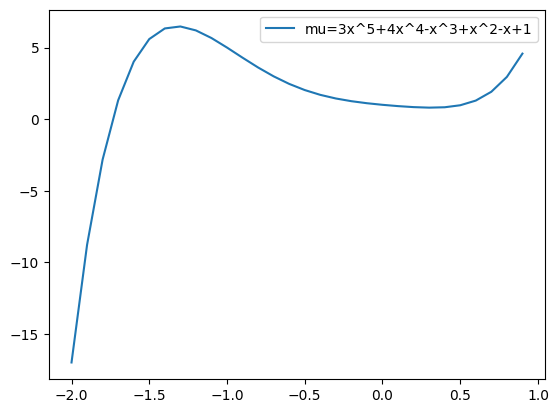

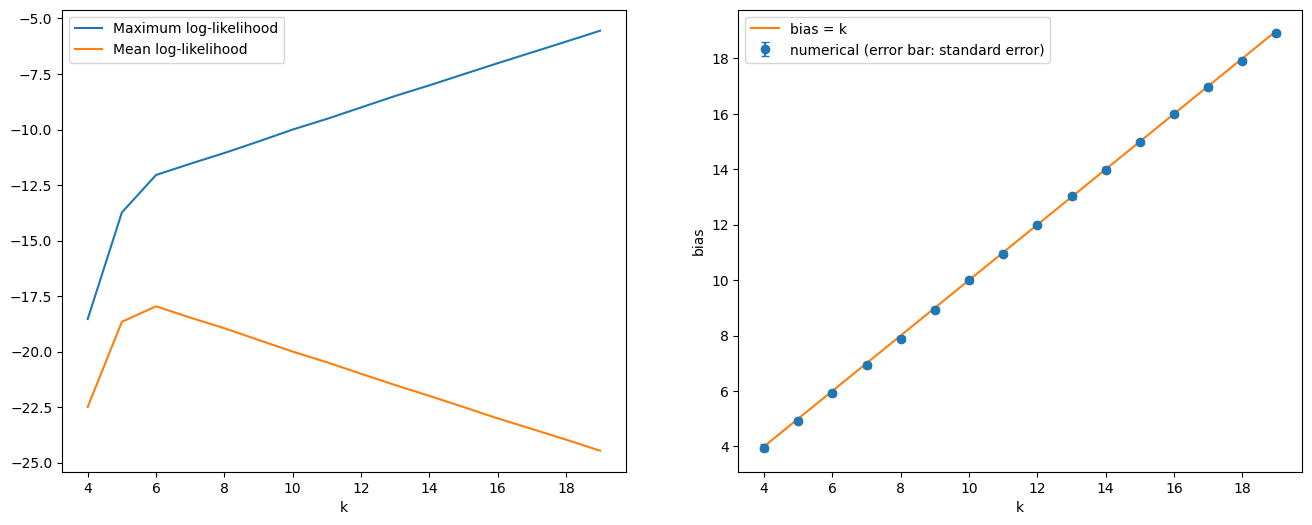

In [6]:
## sys_sample, sampleの数を増やせば増やすほど、真の確率分布での期待値に近づく
## （sys_sample=2000, sample=200 で実行時間は10秒程度）

## 分散は既知とする
import numpy as np
from matplotlib import pyplot as plt

## 乱数のシード（再現性のため固定。変えると図が変わる）
rng = np.random.default_rng(0)

### 真の分布の準備 ###
## Standard Deviation = sigma ##
sigma = 3

## 平均値の関数 ##
#y = 3x**5 + 4x**4 - x**3 + x**2 - x + 1
p = np.poly1d( np.array([3, 4, -1, 1, -1, 1]) )
x = np.arange(-2, 1, 0.1)
n = x.shape[0]      # データ点の数
mu = p(x)           # 各xにおけるYの平均値（真値）
plt.plot(x, mu, label="mu=3x^5+4x^4-x^3+x^2-x+1")
plt.legend()

## 次数 ##
## m_ini <= m < m_ini+m_size
m_ini = 3
m_size = 16

## 最大対数尤度の期待値 E_X を求めるためのデータセット数（試験者の人数）
sys_sample = 2000

## 平均対数尤度 E_Z を求めるためのデータセット数
sample = 200

## バイアス評価のための配列: インデックスは多項式の次数 ##
l_max_avg  = np.zeros(m_size)   # 最大対数尤度の期待値 E_X[l(theta_hat)]
l_mean_avg = np.zeros(m_size)   # 平均対数尤度の期待値 E_X[l*(theta_hat)]
bias       = np.zeros(m_size)   # 両者の差の期待値
bias_se    = np.zeros(m_size)   # 差の標準誤差（モンテカルロ誤差の目安）

## 初回のフィッティング用のデータ生成（E_X 側）##
## モデル選択の意味から、同じデータ Y を全ての次数 m に対して共通に使う
## Y[j, i] : j番目の試験者が得た、x[i] におけるデータ（正規分布）
Y = mu + sigma * rng.standard_normal((sys_sample, n))

for m in range(m_ini, m_ini + m_size):
    ## フィッティング（最小二乗法 = 分散既知の正規分布に対する最尤法）##
    ## 計画行列 V (n x (m+1)) を作り、全試験者分の最小二乗解をまとめて求める
    V = np.vander(x, m + 1)                               # 列は x^m, ..., x, 1
    A = np.linalg.lstsq(V, Y.T, rcond=None)[0]            # A[:, j] : j番目の試験者の係数 theta_hat
    Y_hat = (V @ A).T                                     # Y_hat[j, i] : フィット値 f_m(x[i] | theta_hat_j)

    ## 最大対数尤度 l(theta_hat) の計算 ##
    ## -n/2*log(2pi*sigma**2) は平均対数尤度との差を取るときに消えるので最初から計算しない
    l_max = -np.sum((Y - Y_hat)**2, axis=1) / (2.0 * sigma**2)       # 試験者ごと (sys_sample,)

    ## 平均対数尤度 l*(theta_hat) の計算（E_Z 側）##
    ## Z[j, s, i] : j番目の試験者が将来得る s番目のデータセットの x[i] における値
    Z = mu + sigma * rng.standard_normal((sys_sample, sample, n))
    l_mean = -np.sum((Z - Y_hat[:, None, :])**2, axis=2) / (2.0 * sigma**2)   # (sys_sample, sample)
    l_mean = l_mean.mean(axis=1)                                            # Z について平均 (sys_sample,)

    ## 試験者について平均（E_X）##
    idx = m - m_ini
    l_max_avg[idx]  = l_max.mean()
    l_mean_avg[idx] = l_mean.mean()
    bias[idx]       = (l_max - l_mean).mean()
    bias_se[idx]    = (l_max - l_mean).std(ddof=1) / np.sqrt(sys_sample)

## 図の描画 ##
##モデルの自由パラメータの数はk=(m+1)個

k = np.arange(m_ini + 1, m_ini + m_size + 1)
fig = plt.figure(figsize=(16, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.set_xlabel("k")
ax1.plot(k, l_max_avg, label="Maximum log-likelihood")
ax1.plot(k, l_mean_avg, label="Mean log-likelihood")
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2)
ax2.set_xlabel("k")
ax2.set_ylabel("bias")
ax2.errorbar(k, bias, yerr=bias_se, fmt="o", capsize=3, label="numerical (error bar: standard error)")
ax2.plot(k, k, label="bias = k")
ax2.legend()
fig.show()

print(" k   bias   (standard error)")
for ki, bi, si in zip(k, bias, bias_se):
    print(f"{ki:2d}  {bi:6.2f}  ({si:.2f})")

###**数値実験の結果**###
数値実験の結果から、
$$E_X[l^*(\hat\theta)]=E_X[l(\hat\theta)]-k\tag{4}$$
すなわち
$$(最尤モデルの平均対数尤度の期待値)=(最大対数尤度の期待値)-(モデルの自由パラメータの数)$$
となりそうだ。

平均対数尤度の期待値は、今あるデータで得られる最大対数尤度の期待値と一致しない。
モデルのパラメータの数を上げると、最大対数尤度は増加するが、平均対数尤度の期待値は必ずしも増加しない。

平均対数尤度は、将来に得られる無限個のデータも含めての尤度であるから、良いモデルの選択は、平均対数尤度で評価しなければならない。
今回の場合、平均対数尤度は、$k=6$でピークを持つ。パラメータの数は6個（5次多項式）が良いということだ。今回は、事前に設定した多項式と同じパラメータの数のモデルを選択するのが良さそうだ。しかし、いつも真のパラメータの数と一致するとは限らない。観測値にゆらぎが含まれるので、平均対数尤度の最大を与えるパラメータの数は、本来の数よりも少なくなる傾向がある。
一方、もし、最大対数尤度でモデル選択をするのなら、多項式の次数を上げたモデルは次数の低いモデルを特別な場合として含む（入れ子になっている）ので、最大対数尤度は$k$について単調に増加し、必ず最大の$k$（ここでは$k=19$）を選んでしまう。

問題は、本来、真の確率分布を知らないので、平均対数尤度を知りえないことである。
では、どうすれば良いのか？

数値実験の結果を整理した関係式(4)は、最大対数尤度から自由パラメータの数を引いた$l(\hat\theta)-k$が、最尤モデルの平均対数尤度$l^*(\hat\theta)$の期待値の不偏推定量になることを示している。

この関係式を使えば、モデルの良さを評価できそうだ。

#####**補足1（関係式(4)は期待値についての式である）**#####
関係式(4)は期待値$E_X[\cdot]$についての式であって、1人の試験者が手元のデータから計算する差$l(\hat\theta)-l^*(\hat\theta)$が$k$に等しいという式ではない。実際、この差は試験者ごとに大きくばらつく。補足2の記法を使うと、真の分布を含むモデル（$m\geq5$）では、この差の分散は$n/2$（$n=30$なら標準偏差は約3.9）となる（分散の計算は補足2の演習と同様にできる。真の分布を含まないモデルでは、さらに$\|(I-H)\mu\|^2/\sigma^2$が加わる）。

図のエラーバーは、`sys_sample`人の試験者についての平均の標準誤差（1人あたりの標準偏差を$\sqrt{\mathtt{sys\_sample}}$で割ったもの）であり、`sys_sample`$=2000$では0.09程度である。期待値を精度よく求めるには、それだけ多くの試験者が必要だということである。`sys_sample`を50程度に減らして実行すると、標準誤差が0.6程度になり、点が直線$\mathrm{bias}=k$から目に見えてずれること、また、同じデータ$Y$を全ての次数で共有しているため、そのずれが$k$の間で相関する（全体がまとまって上または下にずれる）ことを確かめてみよう。

#####**補足2（この設定では関係式(4)は厳密に成り立つ）**#####
次回は、関係式(4)を一般の確率モデルに対して$n\rightarrow\infty$の漸近論として導出する。
しかし、今回の数値実験の設定（線形回帰、正規誤差、分散既知）に限れば、関係式(4)は$n\rightarrow\infty$の極限を取らなくても、任意の$n$（ここでは$n=30$）に対して厳密に成り立ち、しかも真の分布を含まないモデル（$m=3,4$）に対しても成り立つ。

最小二乗法によるフィット値は$\hat{y}=HY$と書ける。ここで$H=V(V^TV)^{-1}V^T$は計画行列$V$から決まる$n\times n$の射影行列（ハット行列）で、$H^2=H$, $H^T=H$, $\mathrm{tr}\,H=k$を満たす。$Y=\mu+\epsilon$（$\epsilon$の各成分は独立に$N(0,\sigma^2)$）とすると
$$E_X\left[\|Y-HY\|^2\right]=\|(I-H)\mu\|^2+\sigma^2(n-k),\qquad E_X\left[\|\mu-HY\|^2\right]=\|(I-H)\mu\|^2+\sigma^2 k$$
であり、また、将来のデータ$Z=\mu+\epsilon'$に対して$E_Z\left[\|Z-HY\|^2\right]=n\sigma^2+\|\mu-HY\|^2$である。
これらを$-1/(2\sigma^2)$倍して差を取ると、モデルの誤差$\|(I-H)\mu\|^2$が打ち消し合い、
$$E_X[l(\hat\theta)]-E_X[l^*(\hat\theta)]=\frac{1}{2\sigma^2}\left(2\sigma^2 k\right)=k$$
となる。

**演習（数理系向け）** 上の2つの期待値の式を示しなさい（ヒント：$E[\epsilon^T M\epsilon]=\sigma^2\,\mathrm{tr}\,M$）。また、分散$\sigma^2$が未知で最尤推定量$\hat\sigma^2$に置き換えた場合には、この議論のどこが変わるかを考えなさい。

次回、この関係式の理論的な背景を解説し、モデル選択の評価指標の1つである赤池情報量基準(AIC)を理解する。